# Learning EEG Data and Preprocessing with the MNE Sample

这个 notebook 是给 EEG 初学者的练习。我们使用 MNE 官方 sample 数据学习如何读取 Raw 数据、检查 channel 和 sampling rate、查看 annotations/events、绘制波形和 PSD，并在副本上尝试基础滤波。

这里的 sample 数据不是 bigP3BCI 数据；不要根据它推断 bigP3BCI 的 channel、event code、reference 或正式 preprocessing 参数。正式项目参数仍以老师和 lab 的代码为准。

## 1. Setup

导入 MNE 和绘图库，并显示版本。

In [18]:
from pathlib import Path
import numpy as np
%matplotlib inline
import matplotlib.pyplot as plt
import mne

print('MNE version:', mne.__version__)

MNE version: 1.12.1


## 2. Download and read the MNE sample

第一次运行下面的 cell 时，MNE 会自动下载 sample 数据。数据较大，请确保有足够磁盘空间；这与项目的 bigP3BCI 数据下载是分开的。

In [ ]:
sample_root = Path(mne.datasets.sample.data_path())
sample_raw_path = sample_root / 'MEG' / 'sample' / 'sample_audvis_raw.fif'
raw = mne.io.read_raw_fif(sample_raw_path, preload=False, verbose=False)
print(raw)
print('File:', sample_raw_path)

## 3. Understand the Raw object

`Raw` 表示连续记录。重点检查 sampling rate、时长、channel 数量、channel names 和 MNE 推断的 channel types。

In [19]:
print('Sampling rate:', raw.info['sfreq'], 'Hz')
print('Number of samples:', raw.n_times)
print('Duration:', raw.n_times / raw.info['sfreq'], 'seconds')
print('Number of channels:', len(raw.ch_names))
print('First 20 channel names:', raw.ch_names[:20])
print('Channel type counts:', raw.get_channel_types(unique=True))
print('Detailed channel types:')
print(dict(zip(raw.ch_names, raw.get_channel_types())))

Sampling rate: 600.614990234375 Hz
Number of samples: 166800
Duration: 277.7153462901591 seconds
Number of channels: 376
First 20 channel names: ['MEG 0113', 'MEG 0112', 'MEG 0111', 'MEG 0122', 'MEG 0123', 'MEG 0121', 'MEG 0132', 'MEG 0133', 'MEG 0131', 'MEG 0143', 'MEG 0142', 'MEG 0141', 'MEG 0213', 'MEG 0212', 'MEG 0211', 'MEG 0222', 'MEG 0223', 'MEG 0221', 'MEG 0232', 'MEG 0233']
Channel type counts: ['grad', 'mag', 'stim', 'eeg', 'eog']
Detailed channel types:
{'MEG 0113': 'grad', 'MEG 0112': 'grad', 'MEG 0111': 'mag', 'MEG 0122': 'grad', 'MEG 0123': 'grad', 'MEG 0121': 'mag', 'MEG 0132': 'grad', 'MEG 0133': 'grad', 'MEG 0131': 'mag', 'MEG 0143': 'grad', 'MEG 0142': 'grad', 'MEG 0141': 'mag', 'MEG 0213': 'grad', 'MEG 0212': 'grad', 'MEG 0211': 'mag', 'MEG 0222': 'grad', 'MEG 0223': 'grad', 'MEG 0221': 'mag', 'MEG 0232': 'grad', 'MEG 0233': 'grad', 'MEG 0231': 'mag', 'MEG 0243': 'grad', 'MEG 0242': 'grad', 'MEG 0241': 'mag', 'MEG 0313': 'grad', 'MEG 0312': 'grad', 'MEG 0311': 'mag',

## 4. Channel inventory

channel type 会影响后续处理：EEG、MEG、EOG、STIM 等通道不应被完全相同地处理。

In [20]:
inventory = []
for name, kind in zip(raw.ch_names, raw.get_channel_types()):
    inventory.append({'name': name, 'type': kind, 'unit': raw._orig_units.get(name)})
display(__import__('pandas').DataFrame(inventory))

eeg_picks = mne.pick_types(raw.info, eeg=True, exclude=[])
eeg_names = [raw.ch_names[i] for i in eeg_picks]
print('EEG channels:', len(eeg_names))
print(eeg_names)

,name,type,unit
0,MEG 0113,grad,None
1,MEG 0112,grad,None
2,MEG 0111,mag,None
3,MEG 0122,grad,None
4,MEG 0123,grad,None
...,...,...,...
371,EEG 057,eeg,None
372,EEG 058,eeg,None
373,EEG 059,eeg,None
374,EEG 060,eeg,None


EEG channels: 60
['EEG 001', 'EEG 002', 'EEG 003', 'EEG 004', 'EEG 005', 'EEG 006', 'EEG 007', 'EEG 008', 'EEG 009', 'EEG 010', 'EEG 011', 'EEG 012', 'EEG 013', 'EEG 014', 'EEG 015', 'EEG 016', 'EEG 017', 'EEG 018', 'EEG 019', 'EEG 020', 'EEG 021', 'EEG 022', 'EEG 023', 'EEG 024', 'EEG 025', 'EEG 026', 'EEG 027', 'EEG 028', 'EEG 029', 'EEG 030', 'EEG 031', 'EEG 032', 'EEG 033', 'EEG 034', 'EEG 035', 'EEG 036', 'EEG 037', 'EEG 038', 'EEG 039', 'EEG 040', 'EEG 041', 'EEG 042', 'EEG 043', 'EEG 044', 'EEG 045', 'EEG 046', 'EEG 047', 'EEG 048', 'EEG 049', 'EEG 050', 'EEG 051', 'EEG 052', 'EEG 053', 'EEG 054', 'EEG 055', 'EEG 056', 'EEG 057', 'EEG 058', 'EEG 059', 'EEG 060']


## 5. Annotations and events

`annotations` 通常保存带有 onset、duration 和 description 的时间标记。不要先假设 description 就是 target/non-target；应先观察实际内容。

In [21]:
annotation_df = __import__('pandas').DataFrame({
    'onset': raw.annotations.onset,
    'duration': raw.annotations.duration,
    'description': raw.annotations.description,
})
display(annotation_df.head(20))
print('Number of annotations:', len(annotation_df))
if not annotation_df.empty:
    display(annotation_df['description'].value_counts())
    print('Unique descriptions:', annotation_df['description'].unique().tolist())

events, event_id = mne.events_from_annotations(raw, verbose=False)
if len(events) == 0:
    stim_picks = mne.pick_types(raw.info, stim=True, exclude=[])
    print('No annotation events found.')
    print('Stimulus channels:', [raw.ch_names[i] for i in stim_picks])
    if len(stim_picks):
        try:
            events = mne.find_events(raw, stim_channel=raw.ch_names[stim_picks[0]], verbose=False)
            event_id = {str(code): int(code) for code in np.unique(events[:, 2])}
        except (RuntimeError, ValueError) as exc:
            print(f'Could not extract events from stimulus channel: {exc}')
print('Events shape:', events.shape)
print('Event ID:', event_id)
print('First events:\n', events[:10])

,onset,duration,description


Number of annotations: 0
No annotation events found.
Stimulus channels: ['STI 001', 'STI 002', 'STI 003', 'STI 004', 'STI 005', 'STI 006', 'STI 014', 'STI 015', 'STI 016']
Events shape: (160, 3)
Event ID: {'5': 5}
First events:
 [[28345     0     5]
 [28771     0     5]
 [30025     0     5]
 [30450     0     5]
 [31665     0     5]
 [32101     0     5]
 [33325     0     5]
 [33712     0     5]
 [34089     0     5]
 [34956     0     5]]


## 6. View continuous signals

先看连续信号，再决定是否需要滤波或剔除异常片段。下面显示前 20 秒，并只选择少量 EEG 通道以便阅读。

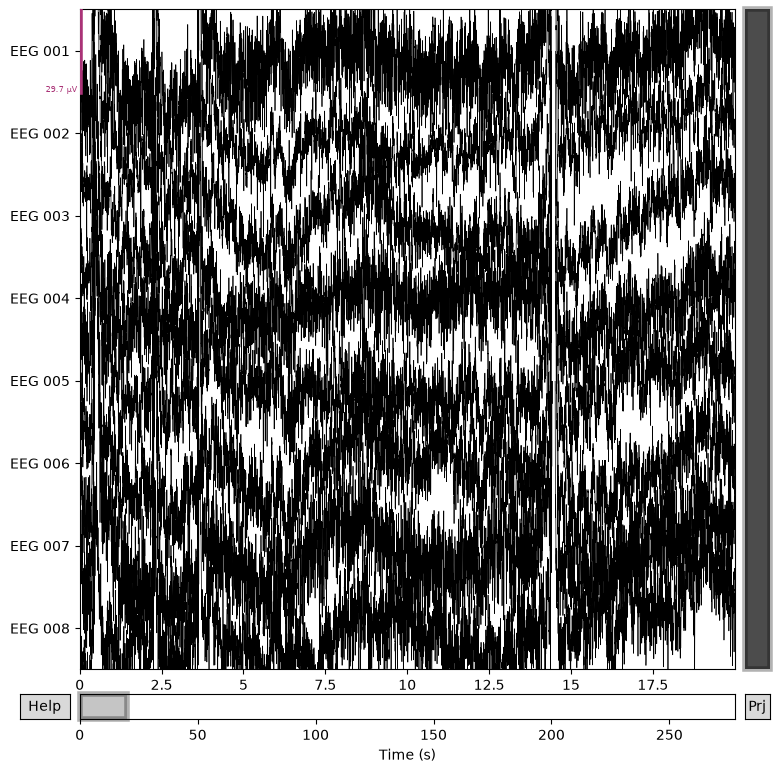

In [22]:
plot_picks = eeg_names[:8]
if plot_picks:
    raw.plot(duration=20, start=0, picks=plot_picks, scalings='auto', title='MNE sample: continuous EEG')
else:
    print('No EEG channels found.')

## 7. Power spectral density (PSD)

PSD 帮助观察不同频率的能量，例如低频漂移、alpha activity，以及可能的 line noise。这里先看 0.5–80 Hz。

Plotting power spectral density (dB=True).
观察重点：频谱中的窄峰可能对应 line noise，但不能仅凭图确定原因。


d:\Anaconda\envs\bigp3bci\Lib\site-packages\mne\viz\utils.py:160: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  (fig or plt).show(**kwargs)


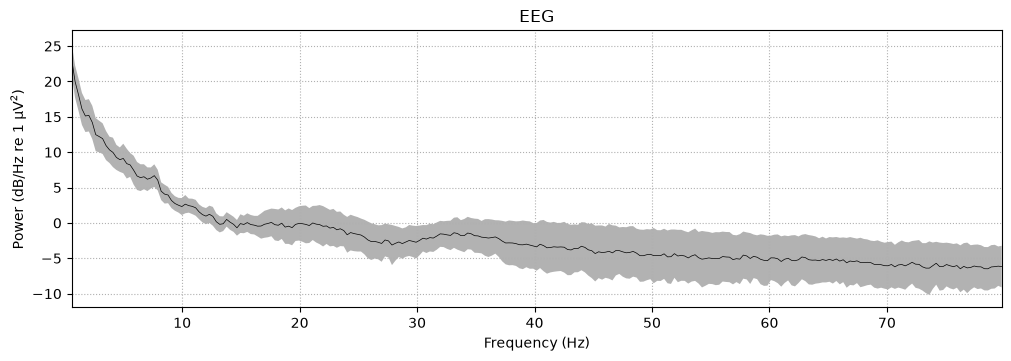

In [23]:
if eeg_picks.size:
    spectrum = raw.compute_psd(fmin=0.5, fmax=80, picks=eeg_picks[:min(20, len(eeg_picks))], verbose=False)
    spectrum.plot(average=True, show=True)
    print('观察重点：频谱中的窄峰可能对应 line noise，但不能仅凭图确定原因。')
else:
    print('No EEG channels found; skip PSD.')

## 8. Exploratory filtering on a copy

滤波会改变信号，因此先复制 Raw。这里仅用于理解 API：notch filter 去除指定频率附近的窄带噪声，band-pass 保留指定频率范围。正式项目参数不能从这个 sample 直接照搬。

Reading 0 ... 166799  =      0.000 ...   277.714 secs...
Created raw_filtered; original raw remains unchanged.


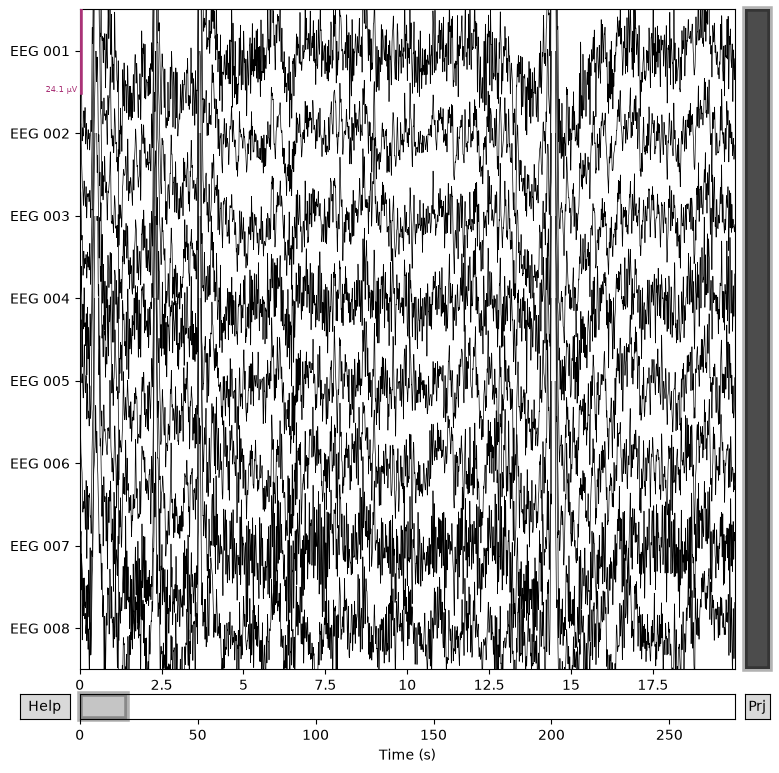

In [24]:
raw_filtered = raw.copy()
if eeg_picks.size:
    # Filtering requires samples in memory; load only the copy, not the original raw object.
    raw_filtered.load_data()
    raw_filtered.notch_filter(freqs=[60], picks=eeg_picks, verbose=False)
    raw_filtered.filter(l_freq=0.5, h_freq=30, picks=eeg_picks, verbose=False)
    print('Created raw_filtered; original raw remains unchanged.')
    raw_filtered.plot(duration=20, start=0, picks=plot_picks, scalings='auto', title='Filtered EEG copy')
else:
    print('No EEG channels found; filtering skipped.')

## 9. Epochs: cutting continuous data around events

Epochs 是以 event 为中心切出的短时间窗。这个 sample 练习展示 API；bigP3BCI 的 event code、target/non-target 映射和 epoch 时间窗必须先由 lab 确认。

In [17]:
if len(events) and event_id:
    first_event_code = next(iter(event_id.values()))
    epochs = mne.Epochs(
        raw, events, event_id=first_event_code, tmin=-0.2, tmax=0.8,
        baseline=(None, 0), preload=False, reject_by_annotation=True, verbose=False
    )
    print(epochs)
    print('Epoch time range:', epochs.times[0], 'to', epochs.times[-1], 'seconds')
else:
    print('No usable events found; cannot create epochs.')

No usable events found; cannot create epochs.


## 10. What to remember for bigP3BCI

- 先确认 EDF 是否能读取，再确认 channel names、types 和 sampling rate。
- annotations 为空时，event 可能在专门的 stimulus/trigger/status channel。
- 不要假设 `StimulusType` 的存储方式，也不要假设 event code。
- 不要覆盖原始 Raw；探索性滤波使用副本。
- 60 Hz notch、band-pass、reference、bad-channel 和 artifact handling 都要以老师/lab 的正式说明为准。
- 下一阶段才根据确认后的 event 定义实现 stimulus-locked epochs 和 target/non-target 标签。